# AIC211 · Topic 2 · Tuần 7 — TV1 (Trí): 3 seed + phân tích lỗi + bảng cuối

**Mục tiêu:** mọi số liệu E3, E4 có trung bình ± độ lệch chuẩn qua 3 seed; phân tích 20 URL sạch bị chặn nhầm ở nguồn B; bảng cuối cho báo cáo.
**Cần có trước:** Nhựt chạy xong **tuần 7** (model D3). Ô 3 và Ô 5 không cần D3, chạy trước được.

| Bước | Làm gì | Ước tính |
|---|---|---|
| 1–2 | Nạp | 2 phút |
| 3 | E3 seed 1, 2 | 5–20 phút, chờ |
| 4 | E4 seed 1, 2 (cần D3) | 5–15 phút, chờ |
| 5 | 20 URL sạch bị chặn nhầm ở B | 2–5 phút |
| 6 | Bảng cuối + hình E3 có sai số | 1 phút |

In [ ]:
# Ô 1 — Cài thư viện + nối Google Drive (chạy lại mỗi lần mở Colab)
import os, sys, importlib
try:
    import google.colab  # chỉ có khi chạy trên Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !pip -q install tldextract rapidfuzz shap xgboost
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/AIC211_URL'   # thư mục chung của nhóm
else:
    ROOT = os.path.abspath('AIC211_URL')          # chạy thử trên máy (không phải Colab)

for d in ['data/raw', 'data/processed', 'src', 'models', 'results', 'figures', 'notebooks']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
sys.path.insert(0, f'{ROOT}/src')
print('ROOT =', ROOT)
print(sorted(os.listdir(ROOT)))

Mounted at /content/drive
ROOT = /content/drive/MyDrive/AIC211_URL
['data', 'figures', 'models', 'notebooks', 'results', 'src']


In [ ]:
# Ô 2 — Nạp code, dữ liệu, 300 URL độc (giống tuần 6), model E3
import common; importlib.reload(common)
from common import *
import json, joblib, random, time
import matplotlib.pyplot as plt
A = pd.read_parquet(f'{ROOT}/data/processed/A.parquet')
B = pd.read_parquet(f'{ROOT}/data/processed/B.parquet')
tr, va, te = (A.split == 'train').values, (A.split == 'val').values, (A.split == 'test').values
import attacks, e3, defenses, d2
for m in (attacks, e3, defenses, d2): importlib.reload(m)
from attacks import *
from e3 import *
from defenses import d1_normalize
from d2 import make_F1D2
benign_domains = set(A[A.label == 0]['reg_domain'])

# Cùng 300 URL độc như tuần 6 (cùng seed) -> so sánh được
N = 300
rng0 = random.Random(0)
MAL = {'A-test': rng0.sample([to_attack_form(u) for u in A[te & (A.label == 1).values]['url_norm']], N),
       'B':      rng0.sample([to_attack_form(u) for u in B[B.label == 1]['url_norm']], N)}
ALL_OPS = FREE_OPS + PAID_OPS
import e4; importlib.reload(e4)
from e4 import load_configs, clean_eval
THR = json.load(open(f'{ROOT}/models/thresholds.json'))
INFO = json.load(open(f'{ROOT}/models/model_info.json'))
MODELS = {n: joblib.load(f'{ROOT}/models/{n}.joblib') for n in ['RF_F1', 'LR_F2']}
SCORE = {n: make_score_fn(m, FEATURIZE[INFO[n]['features']]) for n, m in MODELS.items()}
print('Có model D3 của Nhựt chưa:', os.path.exists(f'{ROOT}/models/RF_F1D2_D1_D3.joblib'))

Có model D3 của Nhựt chưa: True


In [ ]:
# Ô 3 — E3 thêm seed 1 và 2 (seed 0 Nhựt đã chạy tuần 6) -> có trung bình ± độ lệch chuẩn
OPS = {'free': FREE_OPS, 'all': ALL_OPS}
t0 = time.time()
for seed in [1, 2]:
    for model in MODELS:
        for src, urls in MAL.items():
            for mode in ['random', 'greedy']:
                for ops_name, ops in OPS.items():
                    for k in [0, 1, 2, 3, 5]:
                        m, _ = attack_success_rate(urls, SCORE[model], THR[model], k, ops, mode, benign_domains, seed=seed)
                        log_result(ROOT, 'E3', model, src, m, seed=seed, k=k, ops=ops_name, mode=mode)
    print(f'seed {seed} xong ({(time.time() - t0) / 60:.1f} phút)')

seed 1 xong (0.4 phút)
seed 2 xong (0.9 phút)


In [ ]:
# Ô 4 — E4 thêm seed 1 và 2 (cần model D3 của Nhựt; chưa có thì chạy lại ô này sau)
CFG = load_configs(ROOT)
if 'D1+D2+D3' not in CFG:
    print('Chưa có D3 -> chờ Nhựt chạy xong notebook tuần 7 rồi chạy lại ô này.')
else:
    for seed in [1, 2]:
        for name, cfg in CFG.items():
            g, _ = attack_success_rate(MAL['A-test'], cfg['score'], cfg['thr'], 3, ALL_OPS, 'greedy', benign_domains, seed=seed)
            r, _ = attack_success_rate(MAL['A-test'], cfg['score'], cfg['thr'], 3, ALL_OPS, 'random', benign_domains, seed=seed)
            h, _ = attack_success_rate(MAL['A-test'], cfg['score'], cfg['thr'], 1, ['T6'], 'greedy', benign_domains, seed=seed)
            for mode, m, ops in [('greedy', g, 'all'), ('random', r, 'all'), ('greedy', h, 'T6')]:
                log_result(ROOT, 'E4', 'RF', 'A-test', m, defense=name, seed=seed, k=3 if ops == 'all' else 1, ops=ops, mode=mode)
        print(f'seed {seed} xong')

seed 1 xong
seed 2 xong


## Bước 5 — Phân tích lỗi: URL sạch bị chặn nhầm
Tuần 5 thấy RF-F1 chặn nhầm gần 100% URL sạch của nguồn B. Ô này cho số liệu chứng minh: bao nhiêu % trong số đó là trang chủ, độ dài bao nhiêu. Đây là phần **FP/FN theo góc nhìn SOC** mà rubric chấm.

In [ ]:
# Ô 5 — 20 URL SẠCH bị chặn nhầm ở nguồn B: vì sao? (phân tích lỗi cho báo cáo)
lines = []
for name in MODELS:
    s = SCORE[name](['http://' + u for u in B['url_norm']])
    fp = B.assign(score=s)[(B.label == 0).values & (s > THR[name])]
    n_ben = int((B.label == 0).sum())
    home = (fp['rest'].str.len() <= 1).mean()
    print(f'{name}: chặn nhầm {len(fp):,}/{n_ben:,} URL sạch của B ({len(fp) / n_ben:.1%}) | '
          f'{home:.0%} trong số đó là trang chủ (không có path) | độ dài trung vị {fp.url_norm.str.len().median():.0f}')
    top = fp.sort_values('score', ascending=False).head(20)
    lines += [f'--- {name} ---'] + [f'{r.score:.3f} | {r.url_norm}' for r in top.itertuples()]
open(f'{ROOT}/results/FP_B_20.txt', 'w', encoding='utf-8').write('\n'.join(lines))
print('\n'.join(lines[:12]))

RF_F1: chặn nhầm 131,323/131,323 URL sạch của B (100.0%) | 100% trong số đó là trang chủ (không có path) | độ dài trung vị 15
LR_F2: chặn nhầm 5,879/131,323 URL sạch của B (4.5%) | 100% trong số đó là trang chủ (không có path) | độ dài trung vị 13
--- RF_F1 ---
1.000 | nononsensedesign.be
1.000 | suttontrust.com
1.000 | croiconference.org
1.000 | stadtgarten.de
1.000 | anaalexandre.com
1.000 | hellomolly.com
1.000 | briannamaciasco.com
1.000 | pridetoronto.com
1.000 | nadaledarca.com
1.000 | musicincmag.com
1.000 | thetomahawk.com


E3 (recall dưới tấn công, mean ± std):
k                             0      1      2      3      5
model source mode   ops                                    
LR_F2 A-test greedy all   0.360  0.236  0.172  0.129  0.093
                    free  0.360  0.259  0.196  0.148  0.106
             random all   0.360  0.336  0.317  0.306  0.294
                    free  0.360  0.333  0.321  0.308  0.294
      B      greedy all   0.227  0.080  0.026  0.006  0.002
                    free  0.227  0.090  0.033  0.021  0.008
             random all   0.227  0.197  0.173  0.173  0.166
                    free  0.227  0.199  0.169  0.174  0.173
RF_F1 A-test greedy all   0.390  0.053  0.042  0.038  0.034
                    free  0.390  0.050  0.042  0.033  0.032
             random all   0.390  0.270  0.189  0.159  0.069
                    free  0.390  0.244  0.140  0.101  0.044
      B      greedy all   0.460  0.007  0.004  0.003  0.003
                    free  0.460  0.007  0.004  0.004  0.004
 

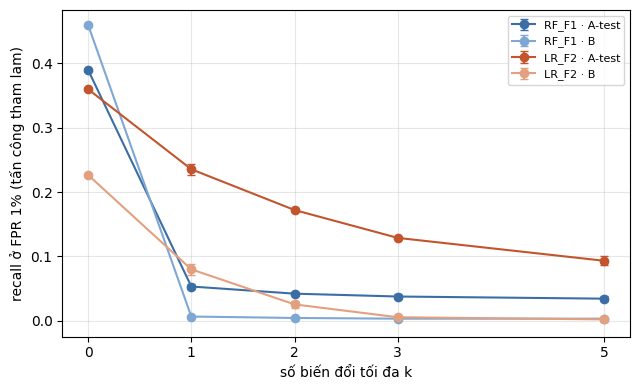

In [ ]:
# Ô 6 — Bảng cuối cho báo cáo: E3 và E4 trung bình ± độ lệch chuẩn qua 3 seed
res = pd.read_csv(f'{ROOT}/results/results.csv')
KEY = ['exp', 'model', 'defense', 'source', 'seed', 'k', 'ops', 'mode']
res = res.drop_duplicates(KEY, keep='last')
os.makedirs(f'{ROOT}/results/tables', exist_ok=True)

e3 = res[res.exp == 'E3'].groupby(['model', 'source', 'mode', 'ops', 'k'])['recall_attack'].agg(['mean', 'std', 'count'])
e3.round(4).to_csv(f'{ROOT}/results/tables/E3_final.csv')
print('E3 (recall dưới tấn công, mean ± std):'); print(e3.round(3).unstack('k')['mean'].to_string())

e4 = res[res.exp == 'E4']
if len(e4):
    t = e4.groupby(['defense', 'mode', 'ops'])[['asr', 'recall_attack', 'mean_queries']].agg(['mean', 'std'])
    t.round(4).to_csv(f'{ROOT}/results/tables/E4_final.csv')
    print('\nE4 (mean ± std qua seed):'); print(t.round(3).to_string())

# Hình E3 có thanh sai số (tham lam, tất cả biến đổi)
fig, ax = plt.subplots(figsize=(6.5, 4))
d = e3.reset_index()
for (model, src), color in {('RF_F1', 'A-test'): '#3b6ea5', ('RF_F1', 'B'): '#7fa7d3',
                            ('LR_F2', 'A-test'): '#c2552d', ('LR_F2', 'B'): '#e3a07f'}.items():
    x = d[(d.model == model) & (d.source == src) & (d['mode'] == 'greedy') & (d.ops == 'all')]
    ax.errorbar(x.k, x['mean'], yerr=x['std'].fillna(0), marker='o', capsize=3, color=color, label=f'{model} · {src}')
ax.set_xlabel('số biến đổi tối đa k'); ax.set_ylabel('recall ở FPR 1% (tấn công tham lam)')
ax.set_xticks([0, 1, 2, 3, 5]); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/E3_recall_vs_k_3seeds.png', dpi=200); plt.show()

## Phân tích bổ sung cho báo cáo (28–30/10)
Các ô dưới chạy sau Ô 6, cần Ô 1 và Ô 2 của notebook này đã chạy trong cùng phiên. Không ô nào gọi `log_result`. Hai ô lưu file bổ sung ngoài FROZEN: `results/E3_T1_split.csv` và `results/tables/FP_B_LR_F2_by_suffix.csv`.

Lưu ý: báo cáo ghi nguồn các URL ví dụ ở mục 7.1 là “Ô T1-05b output”. Đó là ô **Ô 5b** dưới đây.

In [ ]:
# Ô T1-T1split — ASR của T1 theo dạng URL (CHỈ ĐỌC; cần Ô 1, Ô 2 của notebook này chạy trước)
import pandas as pd
urls = MAL['A-test']
def no_path(u):
    rest = u.split('://', 1)[-1]
    return ('/' not in rest) and ('?' not in rest)
mask = [no_path(u) for u in urls]
groups = {'home page, no path': [u for u, m in zip(urls, mask) if m],
          'other URLs':         [u for u, m in zip(urls, mask) if not m]}
rows = []
for model in ['RF_F1', 'LR_F2']:
    for gname, g in groups.items():
        m, _ = attack_success_rate(g, SCORE[model], THR[model], 1, ['T1'], 'greedy', benign_domains, seed=0)
        rows.append({'model': model, 'group': gname, 'n': len(g), 'n_detected': m.get('n_detected'), 'asr': round(m['asr'], 3)})
print(pd.DataFrame(rows).to_string(index=False))

model              group   n  n_detected   asr
RF_F1 home page, no path  55          55 1.000
RF_F1         other URLs 245          62 0.774
LR_F2 home page, no path  55          10 0.700
LR_F2         other URLs 245          98 0.204


In [ ]:
# Ô T1-T1split-save — Lưu kết quả tách T1 theo dạng URL (file bổ sung; không đụng results.csv)
import hashlib, pandas as pd
df = pd.DataFrame(rows)
df['n_evaded'] = (df.asr * df.n_detected).round().astype(int)
p = f'{ROOT}/results/E3_T1_split.csv'
df.to_csv(p, index=False)
sha = hashlib.sha256(open(p, 'rb').read()).hexdigest()
with open(f'{ROOT}/results/FROZEN_manifest.txt', 'a', encoding='utf-8') as m:
    m.write(f'\nE3_T1_split.csv (seed 0, k=1, T1 only, tham lam, 300 URL A-test; chạy 28/10) | sha256 {sha}\n')
print(df.to_string(index=False))

model              group   n  n_detected   asr  n_evaded
RF_F1 home page, no path  55          55 1.000        55
RF_F1         other URLs 245          62 0.774        48
LR_F2 home page, no path  55          10 0.700         7
LR_F2         other URLs 245          98 0.204        20


In [ ]:
# Ô 5b — URL sạch của B bị chặn nhầm, 10 URL điểm cao nhất mỗi model (CHỈ ĐỌC; URL in ra đã defang). Báo cáo ghi nguồn là “Ô T1-05b output”
def defang(u): return 'hxxp://' + u.replace('.', '[.]')
ben = (B.label == 0).values
home_all = (B['rest'].str.len() <= 1).values
print(f'URL sạch của B: {ben.sum():,} | trong đó trang chủ: {(ben & home_all).sum():,} | '
      f'có "/" cuối: {B[ben].url_norm.str.endswith("/").sum():,} | độ dài trung vị: {B[ben].url_norm.str.len().median():.0f}')
for name in MODELS:
    s = SCORE[name](['http://' + u for u in B['url_norm']])
    mask = ben & (s > THR[name])
    fp = B.assign(score=s)[mask]
    home = (fp['rest'].str.len() <= 1)
    print(f'\n{name}: chặn nhầm {len(fp):,}/{ben.sum():,} ({len(fp)/ben.sum():.2%}) | '
          f'trang chủ: {home.sum():,} ({home.mean():.1%}) | có "/" cuối: {fp.url_norm.str.endswith("/").sum():,} | '
          f'độ dài trung vị: {fp.url_norm.str.len().median():.0f}')
    print('  10 URL điểm cao nhất (defang):')
    for r in fp.sort_values('score', ascending=False).head(10).itertuples():
        print(f'   {r.score:.3f} | {defang(r.url_norm)}')

URL sạch của B: 131,323 | trong đó trang chủ: 131,323 | có "/" cuối: 0 | độ dài trung vị: 15

RF_F1: chặn nhầm 131,323/131,323 (100.00%) | trang chủ: 131,323 (100.0%) | có "/" cuối: 0 | độ dài trung vị: 15
  10 URL điểm cao nhất (defang):
   1.000 | hxxp://nononsensedesign[.]be
   1.000 | hxxp://suttontrust[.]com
   1.000 | hxxp://croiconference[.]org
   1.000 | hxxp://stadtgarten[.]de
   1.000 | hxxp://anaalexandre[.]com
   1.000 | hxxp://hellomolly[.]com
   1.000 | hxxp://briannamaciasco[.]com
   1.000 | hxxp://pridetoronto[.]com
   1.000 | hxxp://nadaledarca[.]com
   1.000 | hxxp://musicincmag[.]com

LR_F2: chặn nhầm 5,879/131,323 (4.48%) | trang chủ: 5,879 (100.0%) | có "/" cuối: 0 | độ dài trung vị: 13
  10 URL điểm cao nhất (defang):
   0.999 | hxxp://cs[.]cf[.]ac[.]uk
   0.997 | hxxp://geocode[.]xyz
   0.996 | hxxp://drive[.]ru
   0.994 | hxxp://zagapp[.]com[.]br
   0.992 | hxxp://groupsoftware[.]com[.]br
   0.992 | hxxp://herworld[.]co[.]id
   0.991 | hxxp://topsapp[.]com[.]br


In [ ]:
# Ô T1-05c (tùy chọn) — LR_F2 chặn nhầm theo đuôi tên miền (CHỈ ĐỌC; không in URL)
s = SCORE['LR_F2'](['http://' + u for u in B['url_norm']])
d = B.assign(fp=(s > THR['LR_F2'])).query('label == 0').copy()
d['suffix'] = d['host'].map(lambda h: EXTRACT(h).suffix or '(none)')
g = d.groupby('suffix')['fp'].agg(n='size', n_fp='sum', fpr='mean')
print('Đuôi có >= 300 URL sạch, xếp theo FPR:')
print(g[g.n >= 300].sort_values('fpr', ascending=False).head(15).round(3).to_string())
print('\nTổng FP:', int(g.n_fp.sum()), '| FP thuộc 10 đuôi nhiều FP nhất:', int(g.n_fp.nlargest(10).sum()))
print(g.n_fp.nlargest(10).to_string())

Đuôi có >= 300 URL sạch, xếp theo FPR:
           n  n_fp    fpr
suffix                   
ac.uk    309   183  0.592
com.br   949   347  0.366
io       431    95  0.220
ru       876   193  0.220
de      3274   696  0.213
co.jp    834   173  0.207
it      1563   289  0.185
ch       477    70  0.147
fi       302    43  0.142
be       615    83  0.135
pl       436    56  0.128
com.au  1567   178  0.114
gr       415    46  0.111
in       423    46  0.109
cz       526    56  0.106

Tổng FP: 5879 | FP thuộc 10 đuôi nhiều FP nhất: 3280
suffix
com       963
de        696
com.br    347
it        289
ru        193
ac.uk     183
com.au    178
co.jp     173
nl        140
co.uk     118


In [ ]:
# Ô T1-05d — Lưu bảng FP của LR_F2 theo đuôi (dùng biến g của Ô T1-05c; KHÔNG gọi log_result)
out = g.reset_index().sort_values('n_fp', ascending=False)
out.round(4).to_csv(f'{ROOT}/results/tables/FP_B_LR_F2_by_suffix.csv', index=False)
print(out.head(10).round(3).to_string(index=False))
print('com:', g.loc['com'].round(3).to_dict(), '| tổng URL sạch:', int(g.n.sum()), '| tổng FP:', int(g.n_fp.sum()))

suffix     n  n_fp   fpr
   com 67607   963 0.014
    de  3274   696 0.213
com.br   949   347 0.366
    it  1563   289 0.185
    ru   876   193 0.220
 ac.uk   309   183 0.592
com.au  1567   178 0.114
 co.jp   834   173 0.207
    nl  1526   140 0.092
 co.uk  3785   118 0.031
com: {'n': 67607.0, 'n_fp': 963.0, 'fpr': 0.014} | tổng URL sạch: 131323 | tổng FP: 5879


## Xong tuần 7 khi
- [ ] `results/tables/E3_final.csv`, `E4_final.csv`, hình `E3_recall_vs_k_3seeds.png`
- [ ] `results/FP_B_20.txt` + số liệu % trang chủ
- [ ] Thứ Năm họp: chốt H1, H2, H3 đúng hay sai; chọn ít nhất 1 kết quả âm

Tuần 8: viết báo cáo, README, slide, demo.